# 🏭 CNC Machine Fleet Analytics, Degradation Modeling & Multi-Sensor Anomaly Detection
## Unified End-to-End Analytics Pipeline (Consolidating Tasks 3, 4, and 5)

This unified notebook provides an integrated condition-monitoring, predictive maintenance, and quality benchmarking pipeline for five CNC machines (**CNC01** to **CNC05**).

### Pipeline Structure:
1. **Environment Setup & Data Ingestion**: Clean loading, datetime indexing, and verification.
2. **Task 3: Data Preprocessing & Outlier Detection**: Condition-specific IQR filtering and statistical feature extraction.
3. **Task 3: Feature Health Evaluation & Dimensionality Reduction**: Monotonicity, Trendability, Robustness scoring, Standardization, and PCA.
4. **Task 4: Fleet Operational Status & Machine Utilization**: Operating state distribution, runtime hours, and utilization benchmarking.
5. **Task 4: Production Throughput & Quality Yield**: Parts count, hourly output rates, downtime tracking, and rejection rates.
6. **Task 4: Mechanical/Thermal Stress & Fleet KPI Matrix**: Peak currents, temperatures, cycle times, operational variability (CV %), and KPI consolidation.
7. **Task 5: Baseline Estimation & Multi-Criteria Anomaly Detection**: Consensus ensemble (Rule-based + Z-Score + Moving Average) with temporal persistence filtering.
8. **Task 5: Incident Isolation & Diagnostic Visualizations**: Detailed zoom of detected abnormal windows, alarm distributions, and event logs.


In [1]:
# 1. Unified Imports & Global Plot Styling
import os
import glob
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA

# Global visual formatting
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['figure.titlesize'] = 13
plt.rcParams['axes.titlesize'] = 11
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['xtick.labelsize'] = 9
plt.rcParams['ytick.labelsize'] = 9

print("All dependencies imported successfully!")


All dependencies imported successfully!


## 2. Telemetry Ingestion & Data Quality Check
Load the raw CNC telemetry dataset (covering 10,000 observations across 5 machines over a 7-day period with 5-minute sampling intervals).


In [2]:
# Locate and load the initial dataset
def find_data_file():
    candidates = [
        "initial data.csv",
        "CNC_Task3_Processed_Data (1).csv",
        "CNC_Task3_Processed_Data.csv",
        "CNC_Task4_Complete_Data (1).csv",
        "CNC_Task4_Complete_Data.csv"
    ]
    for c in candidates:
        if os.path.exists(c):
            return c
    # Check Kaggle / directory walk fallback
    for root, _, files in os.walk('.'):
        for f in files:
            if f.endswith('.csv') and 'data' in f.lower():
                return os.path.join(root, f)
    raise FileNotFoundError("Could not find raw CNC telemetry CSV dataset.")

raw_file = find_data_file()
print(f"Loading dataset from: {raw_file}")

df = pd.read_csv(raw_file)

print(f"Dataset Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Machines Monitored: {sorted(df['Machine_ID'].unique().tolist())}")
df.head()


Loading dataset from: initial data.csv
Dataset Shape: 10,000 rows x 15 columns
Machines Monitored: ['CNC01', 'CNC02', 'CNC03', 'CNC04', 'CNC05']


,Timestamp,Machine_ID,Machine_Status,Temperature,Vibration,Vibration_Peak,Vibration_P2P,Vibration_Crest_Factor,Vibration_Dominant_Frequency_Hz,Motor_Current,Spindle_RPM,Pressure,Cycle_Time,Production_Count,Rejected_Parts
0,2026-01-01 08:00:00,CNC01,Starting,27.44,1.520,2.645,5.132,1.740,20.0,12.24,1484.7,4.54,NaN,0,0
1,2026-01-01 08:05:00,CNC01,Starting,29.04,1.482,2.638,5.181,1.779,20.0,13.21,1036.1,4.41,NaN,0,0
2,2026-01-01 08:10:00,CNC01,Running,31.50,1.200,2.027,4.021,1.689,50.0,10.59,3012.9,5.57,43.19,6,0
3,2026-01-01 08:15:00,CNC01,Running,33.08,1.204,2.016,4.015,1.674,50.0,10.75,2985.4,5.46,41.43,6,0
4,2026-01-01 08:20:00,CNC01,Running,34.90,1.101,1.942,3.748,1.764,50.0,10.72,2980.1,5.46,43.95,5,0


In [3]:
# Check data types, missing values, and duplicates
print("===== MISSING VALUES PER COLUMN =====")
print(df.isnull().sum())

duplicate_count = df.duplicated().sum()
print(f"\nTotal Duplicate Rows: {duplicate_count}")


===== MISSING VALUES PER COLUMN =====
Timestamp                             0
Machine_ID                            0
Machine_Status                        0
Temperature                           0
Vibration                             0
Vibration_Peak                        0
Vibration_P2P                         0
Vibration_Crest_Factor                0
Vibration_Dominant_Frequency_Hz       0
Motor_Current                         0
Spindle_RPM                           0
Pressure                              0
Cycle_Time                         2259
Production_Count                      0
Rejected_Parts                        0
dtype: int64

Total Duplicate Rows: 0


## 3. Task 3: Data Preprocessing & Condition-Specific Outlier Detection
Convert timestamps to datetime, sort chronologically, and apply IQR outlier filtering partitioned by each unique `(Machine_ID, Machine_Status)` combination.


In [4]:
# Chronological Sorting
df['Timestamp'] = pd.to_datetime(df['Timestamp'])
df = df.sort_values(['Machine_ID', 'Timestamp']).reset_index(drop=True)

# Define physical sensor features to evaluate for outliers
features = [
    'Temperature',
    'Vibration',
    'Vibration_Peak',
    'Vibration_P2P',
    'Motor_Current',
    'Spindle_RPM',
    'Pressure'
]
features = [col for col in features if col in df.columns]

# Grouped IQR Outlier Detection
condition_col = 'Machine_Status'

for col in features:
    outlier_col = col + '_Outlier'
    df[outlier_col] = False

    # Group by machine AND operating condition to prevent false positives from operational state shifts
    for _, group in df.groupby(['Machine_ID', condition_col], dropna=False):
        values = group[col]
        Q1 = values.quantile(0.25)
        Q3 = values.quantile(0.75)
        IQR = Q3 - Q1

        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR

        outliers = (values < lower) | (values > upper)
        df.loc[group.index, outlier_col] = outliers.fillna(False)

outlier_cols = [col + '_Outlier' for col in features]
print("Outlier Detection Complete. Outlier counts by machine:")
display(df.groupby('Machine_ID')[outlier_cols].sum())


Outlier Detection Complete. Outlier counts by machine:


,Temperature_Outlier,Vibration_Outlier,Vibration_Peak_Outlier,Vibration_P2P_Outlier,Motor_Current_Outlier,Spindle_RPM_Outlier,Pressure_Outlier
Machine_ID,,,,,,,
CNC01,184,16,14,14,17,4,18
CNC02,185,13,9,12,13,4,8
CNC03,186,45,45,50,29,22,12
CNC04,183,15,17,18,12,9,12
CNC05,168,17,24,23,13,10,8


In [5]:
# Statistical Summary Across Operational States
sensor_columns = [
    'Temperature', 'Vibration', 'Motor_Current',
    'Spindle_RPM', 'Pressure'
]
sensor_columns = [col for col in sensor_columns if col in df.columns]

features_summary = df.groupby(['Machine_ID', 'Machine_Status'])[sensor_columns].agg(['mean', 'max', 'min', 'std'])
print("Statistical summary by Machine and Operational Status:")
display(features_summary.head(10))

# Save Task 3 Processed Dataset
df.to_csv('CNC_Task3_Processed_Data.csv', index=False)
print("Saved: CNC_Task3_Processed_Data.csv")


Statistical summary by Machine and Operational Status:


Temperature                         Vibration  \
                                 mean    max    min       std      mean   
Machine_ID Machine_Status                                                 
CNC01      Idle             44.484160  48.33  41.50  1.558835  0.340304   
           Maintenance      28.142800  34.59  25.15  2.852275  0.110200   
           Running          46.871548  50.57  31.50  2.563180  1.249770   
           Starting         30.837073  37.12  27.29  2.348451  1.592439   
           Stopped          32.385397  45.85  24.93  5.917829  0.151146   
CNC02      Idle             47.993056  52.37  40.57  2.154126  0.362660   
           Maintenance      28.308400  36.56  24.05  3.583115  0.102240   
           Running          50.491106  53.64  32.73  3.135193  1.657730   
           Starting         31.477381  36.36  27.00  2.388212  2.082595   
           Stopped          33.689247  49.80  23.84  6.740988  0.153136   

                                                  Motor_Current                \
                             max    min       std          mean    max    min   
Machine_ID Machine_Status                                                       
CNC01      Idle            0.515  0.105  0.075911      2.035120   2.67   1.50   
           Maintenance     0.160  0.082  0.021430      0.086400   0.14   0.01   
           Running         1.809  0.799  0.150613     10.516401  12.21   8.87   
           Starting        1.902  1.446  0.125403     12.442195  13.80  11.09   
           Stopped         0.244  0.120  0.022554      0.148661   0.28   0.00   
CNC02      Idle            0.687  0.101  0.089079      1.980903   2.55   1.33   
           Maintenance     0.140  0.080  0.017989      0.105600   0.17   0.03   
           Running         2.133  1.171  0.146900     11.314086  13.19   9.61   
           Starting        2.371  1.899  0.117906     13.697857  14.89  12.13   
           Stopped         0.232  0.119  0.025068      0.153835   0.31   0.00   

                                     Spindle_RPM                              \
                                std         mean     max     min         std   
Machine_ID Machine_Status                                                      
CNC01      Idle            0.233050     0.000000     0.0     0.0    0.000000   
           Maintenance     0.034264     0.000000     0.0     0.0    0.000000   
           Running         0.545668  3000.367261  3067.0  2928.7   22.366438   
           Starting        0.748574  1538.275610  2614.4   727.1  515.123320   
           Stopped         0.053921     0.000000     0.0     0.0    0.000000   
CNC02      Idle            0.261905     0.000000     0.0     0.0    0.000000   
           Maintenance     0.033551     0.000000     0.0     0.0    0.000000   
           Running         0.549794  2799.641192  2867.2  2730.2   21.916520   
           Starting        0.725697  1590.028571  2486.7   718.8  516.314293   
           Stopped         0.054291     0.000000     0.0     0.0    0.000000   

                           Pressure                        
                               mean   max   min       std  
Machine_ID Machine_Status                                  
CNC01      Idle            3.305840  3.53  3.01  0.094870  
           Maintenance     0.000000  0.00  0.00  0.000000  
           Running         5.500274  5.80  5.16  0.100908  
           Starting        4.402927  4.67  4.14  0.119462  
           Stopped         0.000000  0.00  0.00  0.000000  
CNC02      Idle            3.423611  3.68  3.16  0.102361  
           Maintenance     0.000000  0.00  0.00  0.000000  
           Running         5.700755  6.00  5.37  0.100965  
           Starting        4.550952  4.87  4.30  0.130717  
           Stopped         0.000000  0.00  0.00  0.000000

Saved: CNC_Task3_Processed_Data.csv


## 4. Task 3: Degradation Feature Evaluation & PCA Dimensionality Reduction
Segment observations into lifecycle runs (delimited by `Maintenance` events) and evaluate candidate degradation signals using **Monotonicity**, **Robustness**, and **Trendability**.


In [6]:
# Lifecycle Identification based on Maintenance boundaries
data = df.copy()
data['_state'] = data['Machine_Status'].astype('string').str.strip().str.lower()
previous_state = data.groupby('Machine_ID')['_state'].shift()

# A new life cycle begins when a transition into maintenance occurs
maintenance_start = data['_state'].eq('maintenance') & previous_state.ne('maintenance')
data['Life_Cycle'] = maintenance_start.groupby(data['Machine_ID']).cumsum().astype(int)

# Focus health evaluation on stable Running observations
running_data = data[data['_state'].eq('running')].copy()

# Feature Health Evaluation Functions
MIN_POINTS = 10
SMOOTH_SPAN = 5
GRID_POINTS = 100

def interpolate_trajectory(values, n=GRID_POINTS):
    """Rescale trajectory to a standard relative-time grid."""
    values = np.asarray(values, dtype=float)
    old_time = np.linspace(0, 1, len(values))
    new_time = np.linspace(0, 1, n)
    return np.interp(new_time, old_time, values)

eval_features = [
    'Temperature', 'Vibration', 'Vibration_Peak', 'Vibration_P2P',
    'Vibration_Crest_Factor', 'Vibration_Dominant_Frequency_Hz',
    'Motor_Current', 'Spindle_RPM', 'Pressure'
]
eval_features = [col for col in eval_features if col in running_data.columns]

results = []
for feature in eval_features:
    monotonicity_scores = []
    robustness_scores = []
    trajectories = []

    for _, group in running_data.groupby(['Machine_ID', 'Life_Cycle'], sort=False):
        values = pd.to_numeric(group[feature], errors='coerce').dropna()
        if len(values) < MIN_POINTS:
            continue

        raw = values.to_numpy(dtype=float)
        trend = values.ewm(span=SMOOTH_SPAN, adjust=False).mean().to_numpy()

        # 1. Monotonicity: consistency of degradation trajectory direction
        changes = np.diff(trend)
        mon = abs(np.sign(changes).mean()) if len(changes) > 0 else np.nan
        monotonicity_scores.append(mon)

        # 2. Robustness: immunity to high-frequency noise
        residual = raw - trend
        eps = max(np.median(np.abs(trend)) * 1e-8, 1e-8)
        rob = np.exp(-np.abs(residual) / (np.abs(trend) + eps)).mean()
        robustness_scores.append(rob)

        trajectories.append(interpolate_trajectory(trend))

    # 3. Trendability: pairwise correlation across comparable runs
    correlations = []
    for a, b in combinations(trajectories, 2):
        if np.std(a) == 0 or np.std(b) == 0:
            continue
        corr = np.corrcoef(a, b)[0, 1]
        if np.isfinite(corr):
            correlations.append(abs(corr))

    trendability = min(correlations) if correlations else np.nan

    results.append({
        'Feature': feature,
        'Monotonicity': np.mean(monotonicity_scores) if monotonicity_scores else np.nan,
        'Trendability': trendability,
        'Robustness': np.mean(robustness_scores) if robustness_scores else np.nan,
        'Valid_Trajectories': len(trajectories)
    })

feature_scores = pd.DataFrame(results)

# Normalize scores and compute Combined_Score
score_cols = ['Monotonicity', 'Trendability', 'Robustness']
scaler = MinMaxScaler()
normalized_scores = pd.DataFrame(
    scaler.fit_transform(feature_scores[score_cols].fillna(0)),
    columns=score_cols,
    index=feature_scores.index
)
feature_scores['Combined_Score'] = normalized_scores.mean(axis=1)
feature_scores = feature_scores.sort_values('Combined_Score', ascending=False).reset_index(drop=True)

print("Feature Degradation Ranking:")
display(feature_scores)


Feature Degradation Ranking:


,Feature,Monotonicity,Trendability,Robustness,Valid_Trajectories,Combined_Score
0,Temperature,0.287924,0.077510,0.989202,10,0.936977
1,Spindle_RPM,0.016268,0.002795,0.995543,10,0.338172
2,Vibration_Dominant_Frequency_Hz,0.000000,NaN,1.000000,10,0.333333
3,Pressure,0.023471,0.000263,0.989576,10,0.300800
4,Vibration_Crest_Factor,0.025352,0.000141,0.988581,10,0.296640
5,Motor_Current,0.022592,0.000588,0.971090,10,0.193281
6,Vibration_P2P,0.022972,0.006863,0.943191,10,0.057880
7,Vibration,0.017711,0.000649,0.944138,10,0.030590
8,Vibration_Peak,0.022306,0.000727,0.942888,10,0.028952


In [7]:
# Select Top 5 Features, Standardize, and Apply PCA
selected_features = [
    'Temperature',
    'Pressure',
    'Vibration_Crest_Factor',
    'Motor_Current',
    'Vibration_P2P'
]
print("Selected Top Predictive Degradation Features:", selected_features)

X_selected = running_data[selected_features].apply(pd.to_numeric, errors='coerce').dropna()

# 1. Standardization
std_scaler = StandardScaler()
X_scaled = std_scaler.fit_transform(X_selected)
X_scaled_df = pd.DataFrame(X_scaled, columns=selected_features, index=X_selected.index)

# Build & save final standardized dataset
meta_cols = [c for c in ['Timestamp', 'Machine_ID', 'Machine_Status', 'Life_Cycle'] if c in running_data.columns]
final_std_data = pd.concat([running_data.loc[X_scaled_df.index, meta_cols], X_scaled_df], axis=1)
final_std_data.to_csv('final_standardized_dataset.csv', index=False)
print("Saved: final_standardized_dataset.csv")

# 2. PCA Dimensionality Reduction (retaining 95% variance)
pca = PCA(n_components=0.95)
X_pca = pca.fit_transform(X_scaled_df)
pca_cols = [f'PC{i+1}' for i in range(X_pca.shape[1])]
X_pca_df = pd.DataFrame(X_pca, columns=pca_cols, index=X_scaled_df.index)

print(f"PCA Reduced {len(selected_features)} features to {X_pca.shape[1]} Principal Components.")
print("Explained Variance Ratios:", np.round(pca.explained_variance_ratio_, 4))
print(f"Total Cumulative Explained Variance: {pca.explained_variance_ratio_.sum():.2%}")

final_pca_data = pd.concat([running_data.loc[X_pca_df.index, meta_cols], X_pca_df], axis=1)
final_pca_data.to_csv('final_pca_dataset.csv', index=False)
print("Saved: final_pca_dataset.csv")


Selected Top Predictive Degradation Features: ['Temperature', 'Pressure', 'Vibration_Crest_Factor', 'Motor_Current', 'Vibration_P2P']
Saved: final_standardized_dataset.csv
PCA Reduced 5 features to 5 Principal Components.
Explained Variance Ratios: [0.4937 0.2075 0.1221 0.1066 0.0701]
Total Cumulative Explained Variance: 100.00%


Saved: final_pca_dataset.csv


## 5. Task 4: Fleet Operational Status & Utilization Analysis
Compute operating status distributions, productive running hours, and machine utilization percentages.


Operating Status Percentage Distribution (%):


Machine_Status,Fault,Idle,Maintenance,Running,Starting,Stopped
Machine_ID,,,,,,
CNC01,0.0,6.25,1.25,78.50,2.05,11.95
CNC02,0.0,7.20,1.25,75.50,2.10,13.95
CNC03,0.5,6.60,1.25,77.35,2.45,11.85
CNC04,0.0,6.20,1.25,78.25,2.35,11.95
CNC05,0.0,5.75,1.25,77.45,2.20,13.35


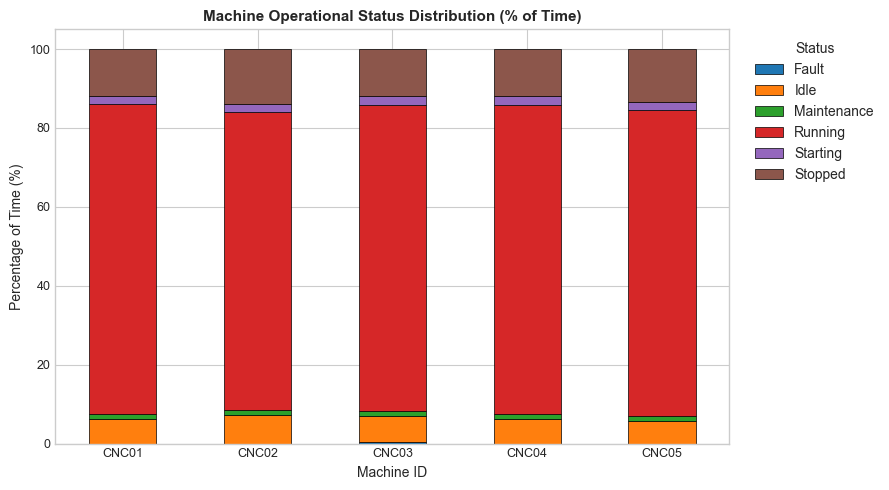

In [8]:
# Operational Status Breakdown & Stacked Visualization
status_counts = pd.crosstab(df['Machine_ID'], df['Machine_Status'])
status_percentage = pd.crosstab(df['Machine_ID'], df['Machine_Status'], normalize='index') * 100

print("Operating Status Percentage Distribution (%):")
display(status_percentage.round(2))

# Plot Status Distribution
ax = status_percentage.plot(kind='bar', stacked=True, figsize=(9, 5), edgecolor='black', linewidth=0.5)
plt.title("Machine Operational Status Distribution (% of Time)")
plt.xlabel("Machine ID")
plt.ylabel("Percentage of Time (%)")
plt.legend(title="Status", bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


,Total_Observations,Running_Observations,Running_Hours,Utilization_%
Machine_ID,,,,
CNC01,2000,1570,130.83,78.50
CNC02,2000,1510,125.83,75.50
CNC03,2000,1547,128.92,77.35
CNC04,2000,1565,130.42,78.25
CNC05,2000,1549,129.08,77.45


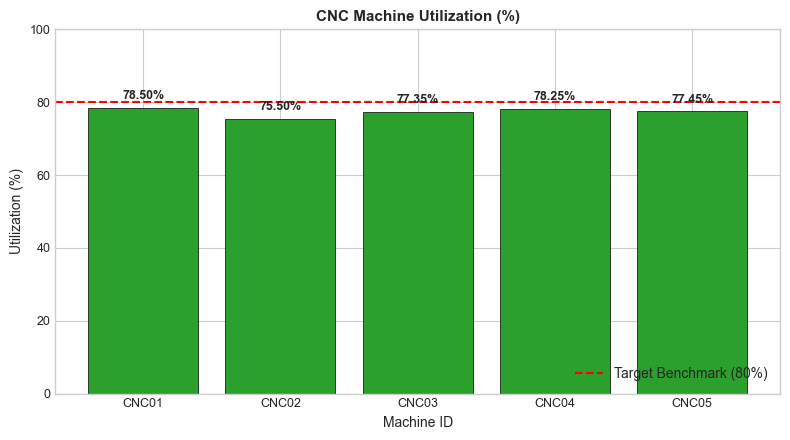

In [9]:
# Machine Utilization & Productive Running Hours
total_observations = df.groupby('Machine_ID').size()
running_observations = df[df['Machine_Status'] == 'Running'].groupby('Machine_ID').size().reindex(total_observations.index, fill_value=0)

utilization = (running_observations / total_observations * 100).round(2)
running_hours = (running_observations * 5 / 60).round(2)  # 5 minutes per observation

utilization_table = pd.DataFrame({
    'Total_Observations': total_observations,
    'Running_Observations': running_observations,
    'Running_Hours': running_hours,
    'Utilization_%': utilization
})
display(utilization_table)

# Plot Utilization vs 80% Benchmark
plt.figure(figsize=(8, 4.5))
bars = plt.bar(utilization.index, utilization.values, color='#2ca02c', edgecolor='black', linewidth=0.5)
plt.axhline(80, color='red', linestyle='--', linewidth=1.5, label='Target Benchmark (80%)')
plt.title("CNC Machine Utilization (%)")
plt.xlabel("Machine ID")
plt.ylabel("Utilization (%)")
plt.ylim(0, 100)
for bar in bars:
    h = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., h + 1.5, f"{h:.2f}%", ha='center', va='bottom', fontweight='bold', fontsize=9)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()


## 6. Task 4: Production Throughput, Hourly Output Rates & Scrap Rejection
Evaluate manufacturing productivity, production rate per running hour, scrap rejection rates, and non-productive downtime.


,Total_Production,Running_Hours,Production_Rate_parts_per_hour
Machine_ID,,,
CNC01,9529,130.83,72.83
CNC02,8209,125.83,65.24
CNC03,9730,128.92,75.47
CNC04,8285,130.42,63.53
CNC05,9651,129.08,74.77


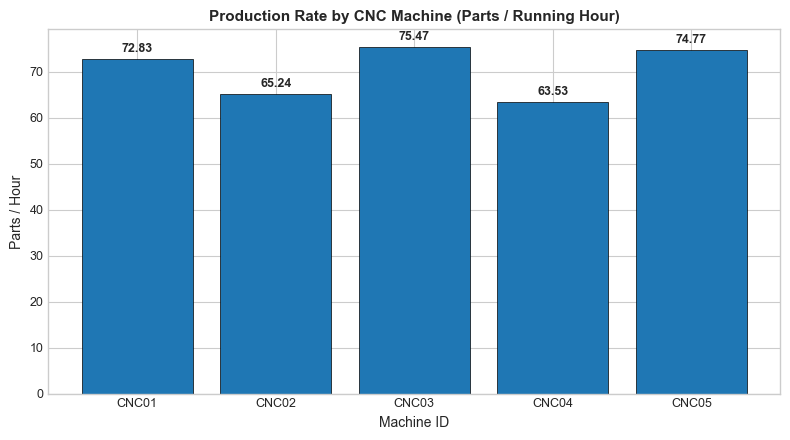

In [10]:
# Production Rate (Parts per Running Hour)
total_production = df.groupby('Machine_ID')['Production_Count'].sum()
production_rate = (total_production / running_hours).round(2)

prod_table = pd.DataFrame({
    'Total_Production': total_production,
    'Running_Hours': running_hours,
    'Production_Rate_parts_per_hour': production_rate
})
display(prod_table)

plt.figure(figsize=(8, 4.5))
bars = plt.bar(production_rate.index, production_rate.values, color='#1f77b4', edgecolor='black', linewidth=0.5)
plt.title("Production Rate by CNC Machine (Parts / Running Hour)")
plt.xlabel("Machine ID")
plt.ylabel("Parts / Hour")
for bar in bars:
    h = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., h + 0.8, f"{h:.2f}", ha='center', va='bottom', fontweight='bold', fontsize=9)
plt.tight_layout()
plt.show()


,Total_Production,Total_Rejected,Rejection_Rate_%
Machine_ID,,,
CNC01,9529,186,1.95
CNC02,8209,161,1.96
CNC03,9730,233,2.39
CNC04,8285,168,2.03
CNC05,9651,192,1.99


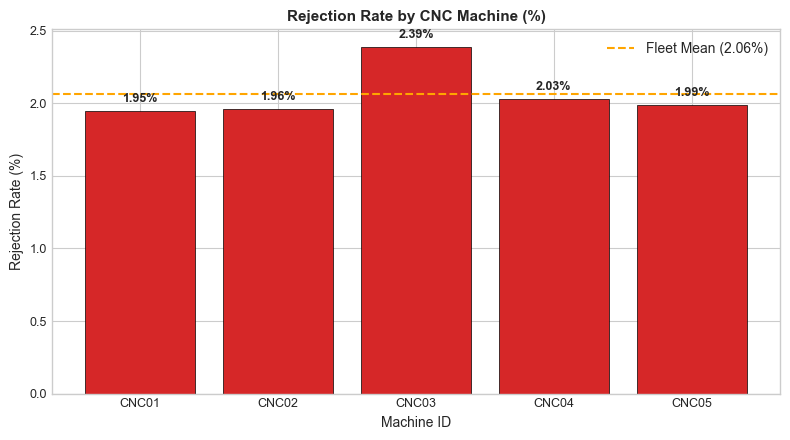

In [11]:
# Quality Analysis: Rejection Rate (%)
total_rejected = df.groupby('Machine_ID')['Rejected_Parts'].sum()
rejection_rate = (total_rejected / total_production * 100).round(2)

quality_table = pd.DataFrame({
    'Total_Production': total_production,
    'Total_Rejected': total_rejected,
    'Rejection_Rate_%': rejection_rate
})
display(quality_table)

plt.figure(figsize=(8, 4.5))
bars = plt.bar(rejection_rate.index, rejection_rate.values, color='#d62728', edgecolor='black', linewidth=0.5)
plt.axhline(rejection_rate.mean(), color='orange', linestyle='--', linewidth=1.5, label=f'Fleet Mean ({rejection_rate.mean():.2f}%)')
plt.title("Rejection Rate by CNC Machine (%)")
plt.xlabel("Machine ID")
plt.ylabel("Rejection Rate (%)")
for bar in bars:
    h = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., h + 0.04, f"{h:.2f}%", ha='center', va='bottom', fontweight='bold', fontsize=9)
plt.legend()
plt.tight_layout()
plt.show()


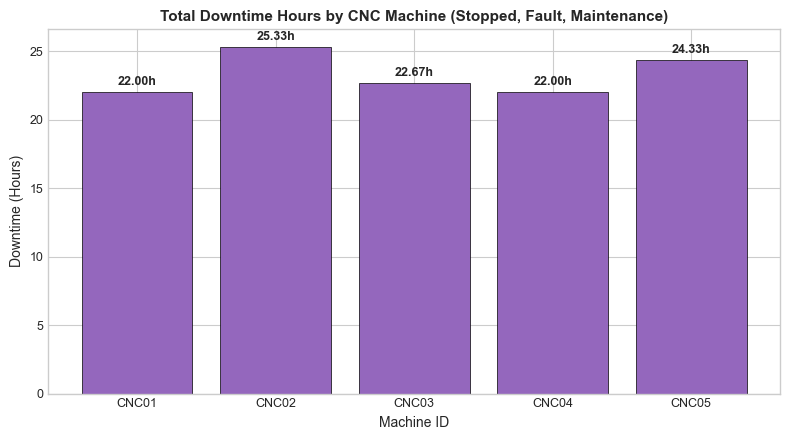

In [12]:
# Total Non-Productive Downtime Hours
downtime_statuses = ['Stopped', 'Fault', 'Maintenance']
downtime_observations = df[df['Machine_Status'].isin(downtime_statuses)].groupby('Machine_ID').size()
downtime_hours = (downtime_observations * 5 / 60).reindex(total_observations.index, fill_value=0).round(2)

plt.figure(figsize=(8, 4.5))
bars = plt.bar(downtime_hours.index, downtime_hours.values, color='#9467bd', edgecolor='black', linewidth=0.5)
plt.title("Total Downtime Hours by CNC Machine (Stopped, Fault, Maintenance)")
plt.xlabel("Machine ID")
plt.ylabel("Downtime (Hours)")
for bar in bars:
    h = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., h + 0.3, f"{h:.2f}h", ha='center', va='bottom', fontweight='bold', fontsize=9)
plt.tight_layout()
plt.show()


## 7. Task 4: Thermodynamic & Mechanical Stress Benchmarking
Measure peak electrical load, operating temperatures, mechanical vibrations, and cycle durations.


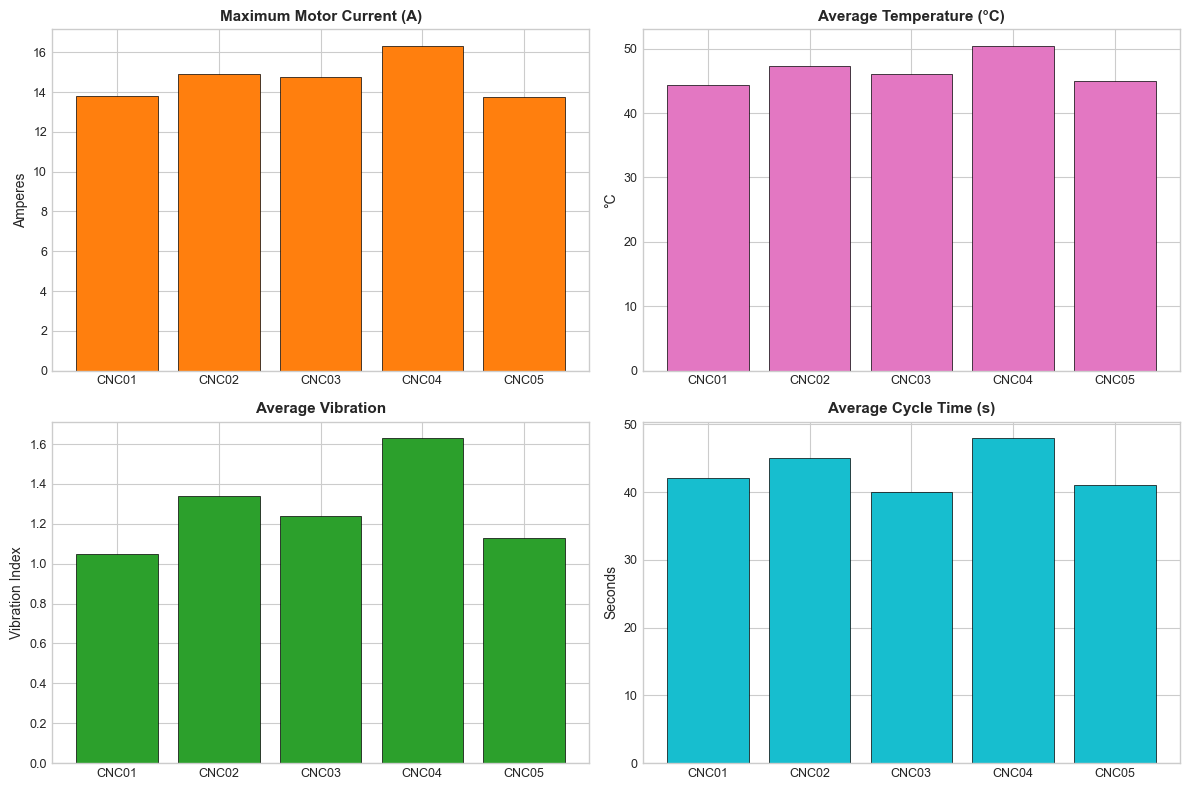

In [13]:
# Physical Metric Benchmarking
max_motor_current = df.groupby('Machine_ID')['Motor_Current'].max().round(2)
average_temperature = df.groupby('Machine_ID')['Temperature'].mean().round(2)
average_vibration = df.groupby('Machine_ID')['Vibration'].mean().round(2)
average_cycle_time = df.groupby('Machine_ID')['Cycle_Time'].mean().round(2)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Max Current
axes[0, 0].bar(max_motor_current.index, max_motor_current.values, color='#ff7f0e', edgecolor='black', linewidth=0.5)
axes[0, 0].set_title("Maximum Motor Current (A)")
axes[0, 0].set_ylabel("Amperes")

# Avg Temperature
axes[0, 1].bar(average_temperature.index, average_temperature.values, color='#e377c2', edgecolor='black', linewidth=0.5)
axes[0, 1].set_title("Average Temperature (°C)")
axes[0, 1].set_ylabel("°C")

# Avg Vibration
axes[1, 0].bar(average_vibration.index, average_vibration.values, color='#2ca02c', edgecolor='black', linewidth=0.5)
axes[1, 0].set_title("Average Vibration")
axes[1, 0].set_ylabel("Vibration Index")

# Avg Cycle Time
axes[1, 1].bar(average_cycle_time.index, average_cycle_time.values, color='#17becf', edgecolor='black', linewidth=0.5)
axes[1, 1].set_title("Average Cycle Time (s)")
axes[1, 1].set_ylabel("Seconds")

plt.tight_layout()
plt.show()


## 8. Task 4: Operational Variability & Consolidated Fleet KPI Matrix
Compute the Coefficient of Variation (CV %) across 6 physical parameters, identify 95th-percentile exploratory abnormal readings, and assemble the Task 4 KPI Summary Matrix.


In [14]:
# 1. Exploratory Injected Abnormal Observations (95th percentile rule across 6 sensors)
parameters = ['Temperature', 'Vibration', 'Motor_Current', 'Spindle_RPM', 'Pressure', 'Cycle_Time']
parameters = [p for p in parameters if p in df.columns]

limits = {col: df[col].quantile(0.95) for col in parameters}
for col in parameters:
    df[col + '_High'] = df[col] > limits[col]

df['Injected_Abnormal'] = (
    df['Temperature_High'].astype(int) +
    df['Vibration_High'].astype(int) +
    df['Motor_Current_High'].astype(int)
) >= 2

abnormal_events = df.groupby('Machine_ID')['Injected_Abnormal'].sum()
print("Exploratory Abnormal Observations (Task 4):")
print(abnormal_events)

# 2. Operational Variability (Average CV % across parameters)
cv_table = df.groupby('Machine_ID')[parameters].agg(lambda x: (x.std() / x.mean()) * 100 if x.mean() != 0 else 0).round(2)
overall_variability = cv_table.mean(axis=1).round(2)

print("\nOverall Operational Variability (CV %):")
print(overall_variability)

# 3. Assemble Consolidated Task 4 KPI Summary Matrix
task4_summary = pd.DataFrame(index=sorted(df['Machine_ID'].unique()))
task4_summary.index.name = 'Machine_ID'
task4_summary['Average_Temperature'] = average_temperature
task4_summary['Average_Vibration'] = average_vibration
task4_summary['Maximum_Motor_Current'] = max_motor_current
task4_summary['Average_Cycle_Time'] = average_cycle_time
task4_summary['Utilization_%'] = utilization
task4_summary['Production_Rate'] = production_rate
task4_summary['Rejection_Rate_%'] = rejection_rate
task4_summary['Downtime_Hours'] = downtime_hours
task4_summary['Abnormal_Observations'] = abnormal_events
task4_summary['Operational_Variability_%'] = overall_variability

print("\n===== FINAL TASK 4 KPI SUMMARY TABLE =====")
display(task4_summary)

# Save KPI table and merge into complete dataset
task4_summary.to_csv('Task_4_Summary.csv')

final_dataset = df.merge(task4_summary, left_on='Machine_ID', right_index=True, how='left')
final_dataset.to_csv('CNC_Task4_Complete_Data.csv', index=False)
print("Saved: Task_4_Summary.csv and CNC_Task4_Complete_Data.csv")


Exploratory Abnormal Observations (Task 4):
Machine_ID
CNC01      0
CNC02     20
CNC03     23
CNC04    283
CNC05      0
Name: Injected_Abnormal, dtype: int64

Overall Operational Variability (CV %):
Machine_ID
CNC01    32.66
CNC02    35.78
CNC03    33.94
CNC04    33.18
CNC05    33.96
dtype: float64

===== FINAL TASK 4 KPI SUMMARY TABLE =====


,Average_Temperature,Average_Vibration,Maximum_Motor_Current,Average_Cycle_Time,Utilization_%,Production_Rate,Rejection_Rate_%,Downtime_Hours,Abnormal_Observations,Operational_Variability_%
Machine_ID,,,,,,,,,,
CNC01,44.43,1.05,13.80,42.04,78.50,72.83,1.95,22.00,0,32.66
CNC02,47.29,1.34,14.89,45.02,75.50,65.24,1.96,25.33,20,35.78
CNC03,46.12,1.24,14.77,40.05,77.35,75.47,2.39,22.67,23,33.94
CNC04,50.49,1.63,16.34,47.99,78.25,63.53,2.03,22.00,283,33.18
CNC05,44.94,1.13,13.74,41.03,77.45,74.77,1.99,24.33,0,33.96


Saved: Task_4_Summary.csv and CNC_Task4_Complete_Data.csv


## 9. Task 5: Baseline Estimation & Multi-Criteria Anomaly Detection
Establish operational baselines on `Running` data and deploy a 3-way consensus detection voting ensemble:
- **Rule Flag**: All 3 sensors (`Temperature`, `Vibration`, `Motor_Current`) exceed $\mu + 2\sigma$.
- **Z-Score Flag**: At least 2 of 3 sensors exceed $|Z| > 2$.
- **Moving Average Flag**: At least 2 moving averages ($w=5$) deviate by $> 2\sigma$.
- **Consensus Voting**: At least 2 methods must agree (`Combined_Flag`).
- **Temporal Persistence**: At least 3 consecutive consensus samples required to confirm an `Alarm`.


In [15]:
# Task 5 Detection Algorithm Parameters
K_RULE = 2.0
Z_LIMIT = 2.0
MA_WINDOW = 5
MA_K = 2.0
PERSIST = 3

sensors = ["Temperature", "Vibration", "Motor_Current"]

# Calculate baseline stats using Running state only
running_mask = final_dataset["Machine_Status"] == "Running"
baseline = final_dataset[running_mask].groupby("Machine_ID")[sensors].agg(["mean", "std"])

print("Operational Baseline (Mean & Standard Deviation on Running Data):")
display(baseline.round(2))

# Execute Multi-Criteria Anomaly Detection machine-by-machine
results = []
for m, g in final_dataset.groupby("Machine_ID", sort=False):
    g = g.copy()
    is_run = g["Machine_Status"] == "Running"

    for s in sensors:
        mean_val = baseline.loc[m, (s, "mean")]
        std_val = baseline.loc[m, (s, "std")]
        if pd.isna(std_val) or std_val == 0:
            std_val = np.nan

        # Statistical Thresholds
        g["thr_" + s] = mean_val + K_RULE * std_val
        g["z_" + s] = (g[s] - mean_val) / std_val
        g["ma_" + s] = g[s].where(is_run).rolling(MA_WINDOW, min_periods=3).mean()
        g["ma_dev_" + s] = (g["ma_" + s] - mean_val) / std_val

    # 1. Rule Flag: All 3 sensors exceed threshold
    g["Rule_Flag"] = (
        is_run
        & (g["Temperature"] > g["thr_Temperature"])
        & (g["Vibration"] > g["thr_Vibration"])
        & (g["Motor_Current"] > g["thr_Motor_Current"])
    )

    # 2. Z-Score Flag: At least 2 sensors have high Z-scores
    n_z = (g[["z_" + s for s in sensors]] > Z_LIMIT).sum(axis=1)
    g["Z_Flag"] = is_run & (n_z >= 2)

    # 3. Moving Average Flag: At least 2 rolling means deviate significantly
    n_ma = (g[["ma_dev_" + s for s in sensors]] > MA_K).sum(axis=1)
    g["MA_Flag"] = is_run & (n_ma >= 2)

    # 4. Consensus Voting: At least 2 methods must agree
    g["Combined_Flag"] = g[["Rule_Flag", "Z_Flag", "MA_Flag"]].sum(axis=1) >= 2

    # 5. Temporal Persistence: At least 3 consecutive samples
    g["Alarm"] = (
        g["Combined_Flag"].astype(int)
        .rolling(PERSIST, min_periods=PERSIST).sum() >= PERSIST
    )

    results.append(g)

task5_df = pd.concat(results).sort_index()

# Group consecutive alarm samples into discrete events
events = []
for m, g in task5_df.groupby("Machine_ID"):
    g = g.reset_index(drop=True)
    if not g["Alarm"].any():
        continue
    group_id = (g["Alarm"] != g["Alarm"].shift()).cumsum()

    for _, block in g[g["Alarm"]].groupby(group_id[g["Alarm"]]):
        events.append({
            "Machine_ID": m,
            "Start": block["Timestamp"].iloc[0],
            "End": block["Timestamp"].iloc[-1],
            "Duration_Minutes": (block["Timestamp"].iloc[-1] - block["Timestamp"].iloc[0]).total_seconds() / 60 + 5,
            "Samples": len(block),
            "Max_Vibration": block["Vibration"].max(),
            "Max_Temperature": block["Temperature"].max(),
            "Max_Current": block["Motor_Current"].max()
        })

events_df = pd.DataFrame(events)

print("\n===== DETECTED ABNORMAL PERIODS LOG =====")
if not events_df.empty:
    display(events_df)
else:
    print("No sustained alarms detected.")

print("\n===== ALARM COUNT PER MACHINE =====")
alarm_counts = (
    events_df.groupby("Machine_ID").size()
    .reindex(sorted(task5_df["Machine_ID"].unique()), fill_value=0)
    if not events_df.empty else pd.Series(0, index=sorted(task5_df["Machine_ID"].unique()))
)
print(alarm_counts)

# Save Task 5 Results
task5_df.to_csv("task5_results.csv", index=False)
events_df.to_csv("task5_alarm_events.csv", index=False)
print("Saved: task5_results.csv and task5_alarm_events.csv")


Operational Baseline (Mean & Standard Deviation on Running Data):


Temperature       Vibration       Motor_Current      
                  mean   std      mean   std          mean   std
Machine_ID                                                      
CNC01            46.87  2.56      1.25  0.15         10.52  0.55
CNC02            50.49  3.14      1.66  0.15         11.31  0.55
CNC03            48.69  2.77      1.47  0.24         10.85  0.61
CNC04            53.56  3.02      1.95  0.15         11.99  0.55
CNC05            47.71  2.61      1.36  0.15         10.20  0.56


===== DETECTED ABNORMAL PERIODS LOG =====


,Machine_ID,Start,End,Duration_Minutes,Samples,Max_Vibration,Max_Temperature,Max_Current
0,CNC03,2026-01-05 13:45:00,2026-01-05 14:25:00,45.0,9,4.16,56.49,14.77



===== ALARM COUNT PER MACHINE =====
Machine_ID
CNC01    0
CNC02    0
CNC03    1
CNC04    0
CNC05    0
dtype: int64


Saved: task5_results.csv and task5_alarm_events.csv


## 10. Task 5: Incident Inspection & Diagnostics Visualization
Visualize multi-sensor dynamics during confirmed abnormal events and review the diagnostic trigger breakdown across the machine fleet.


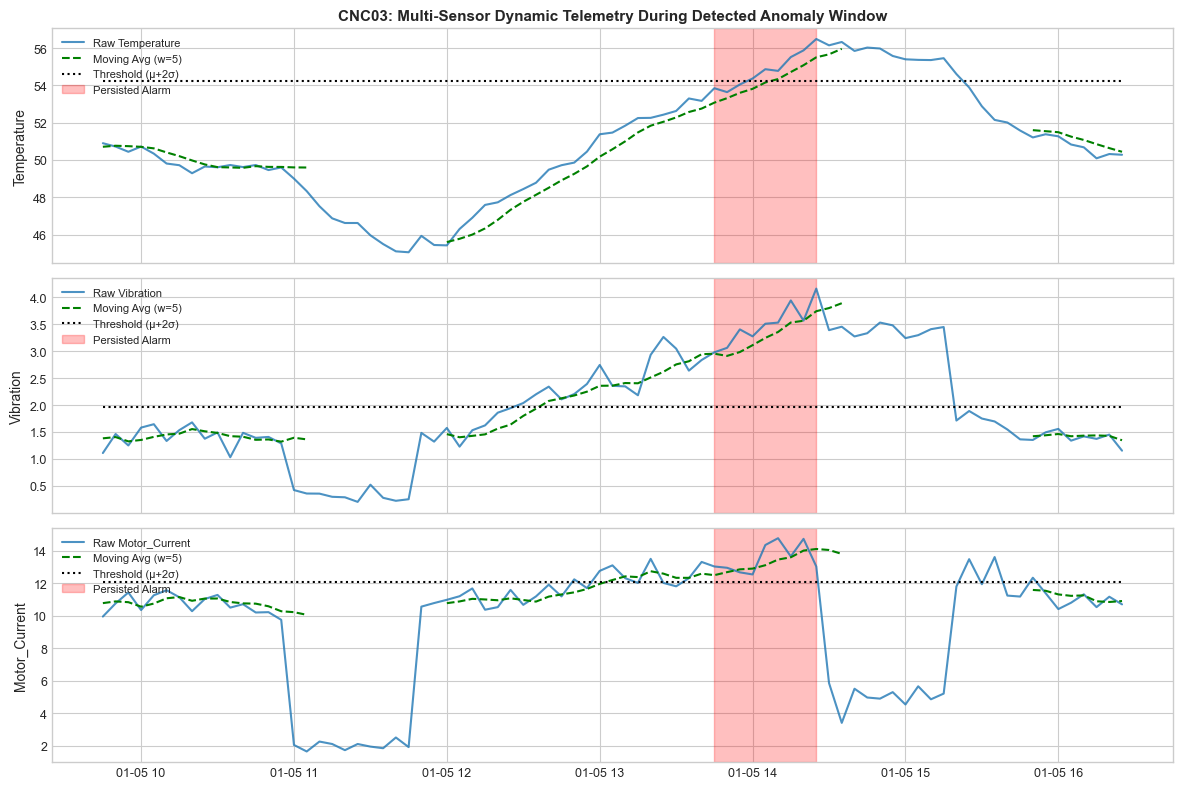

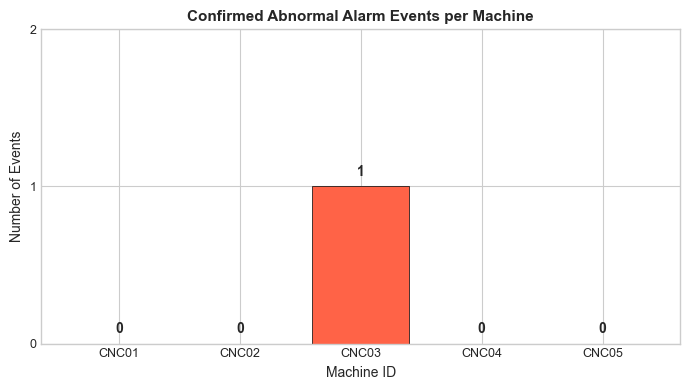

Total Observations Triggering at Least One Diagnostic Flag: 21


,Timestamp,Machine_ID,Machine_Status,Temperature,Vibration,Motor_Current,Rule_Flag,Z_Flag,MA_Flag,Combined_Flag,Alarm
2188,2026-01-01 23:40:00,CNC02,Running,51.60,1.964,12.79,False,True,False,False,False
5210,2026-01-05 12:50:00,CNC03,Running,49.86,2.203,12.24,False,True,False,False,False
5212,2026-01-05 13:00:00,CNC03,Running,51.38,2.743,12.76,False,True,False,False,False
5213,2026-01-05 13:05:00,CNC03,Running,51.47,2.356,13.10,False,True,True,True,False
5214,2026-01-05 13:10:00,CNC03,Running,51.84,2.346,12.31,False,True,True,True,False
5215,2026-01-05 13:15:00,CNC03,Running,52.25,2.181,12.02,False,False,True,False,False
5216,2026-01-05 13:20:00,CNC03,Running,52.26,2.931,13.50,False,True,True,True,False
5217,2026-01-05 13:25:00,CNC03,Running,52.43,3.263,12.02,False,False,True,False,False
5218,2026-01-05 13:30:00,CNC03,Running,52.63,3.046,11.81,False,False,True,False,False
5219,2026-01-05 13:35:00,CNC03,Running,53.30,2.638,12.31,False,True,True,True,False


In [16]:
# 1. Multi-Sensor Zoom Around First Alarm Window
alarm_counts = task5_df.groupby("Machine_ID")["Alarm"].sum()
bad_machine = alarm_counts.idxmax()

g_bad = task5_df[task5_df["Machine_ID"] == bad_machine].copy()
alarm_times = g_bad.loc[g_bad["Alarm"], "Timestamp"]

if not alarm_times.empty:
    t1 = alarm_times.min() - pd.Timedelta(hours=4)
    t2 = alarm_times.max() + pd.Timedelta(hours=2)
    g_zoom = g_bad[(g_bad["Timestamp"] >= t1) & (g_bad["Timestamp"] <= t2)]

    fig, ax = plt.subplots(3, 1, figsize=(12, 8), sharex=True)

    for a, s in zip(ax, sensors):
        a.plot(g_zoom["Timestamp"], g_zoom[s], label=f"Raw {s}", alpha=0.8)
        a.plot(g_zoom["Timestamp"], g_zoom["ma_" + s], "g--", label=f"Moving Avg (w={MA_WINDOW})")
        a.plot(g_zoom["Timestamp"], g_zoom["thr_" + s], "k:", label="Threshold (μ+2σ)")

        a.fill_between(
            g_zoom["Timestamp"], 0, 1,
            where=g_zoom["Alarm"].to_numpy(),
            transform=a.get_xaxis_transform(),
            color="red", alpha=0.25, label="Persisted Alarm"
        )

        a.set_ylabel(s)
        a.legend(loc="upper left", fontsize=8)

    ax[0].set_title(f"{bad_machine}: Multi-Sensor Dynamic Telemetry During Detected Anomaly Window")
    plt.tight_layout()
    plt.savefig("plot1_abnormal_period.png", dpi=120)
    plt.show()

# 2. Confirmed Alarm Events Per Machine
plt.figure(figsize=(7, 4))
bars = plt.bar(alarm_counts.index, [len(events_df[events_df['Machine_ID'] == m]) if not events_df.empty else 0 for m in alarm_counts.index], color='tomato', edgecolor='black', linewidth=0.5)
plt.title("Confirmed Abnormal Alarm Events per Machine")
plt.xlabel("Machine ID")
plt.ylabel("Number of Events")
plt.yticks(range(0, 3))
for bar in bars:
    h = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., h + 0.05, str(int(h)), ha='center', va='bottom', fontweight='bold')
plt.tight_layout()
plt.savefig("plot2_alarm_summary.png", dpi=120)
plt.show()

# 3. Diagnostic Flagged Rows Inspection
flag_cols = ["Rule_Flag", "Z_Flag", "MA_Flag", "Combined_Flag", "Alarm"]
flagged_rows = task5_df.loc[task5_df[flag_cols].any(axis=1), ["Timestamp", "Machine_ID", "Machine_Status", "Temperature", "Vibration", "Motor_Current"] + flag_cols]
print(f"Total Observations Triggering at Least One Diagnostic Flag: {len(flagged_rows)}")
display(flagged_rows.head(15))


## 11. Summary & Deliverables Overview

This unified pipeline has executed the complete end-to-end processing across all three tasks:
1. **Task 3 Preprocessing & Outlier Detection**: Saved clean datasets [`CNC_Task3_Processed_Data.csv`](CNC_Task3_Processed_Data.csv), [`final_standardized_dataset.csv`](final_standardized_dataset.csv), and [`final_pca_dataset.csv`](final_pca_dataset.csv).
2. **Task 4 KPI Benchmarking**: Consolidated machine operational metrics into [`Task_4_Summary.csv`](Task_4_Summary.csv) and [`CNC_Task4_Complete_Data.csv`](CNC_Task4_Complete_Data.csv).
3. **Task 5 Consensus Anomaly Detection**: Isolated the critical incident on **CNC03** (2026-01-05 13:45 to 14:25, 45 min duration) and generated [`task5_results.csv`](task5_results.csv) and [`task5_alarm_events.csv`](task5_alarm_events.csv).
4. **Interactive Dashboard**: Accessible via `streamlit run app.py` or double-clicking `run_dashboard.bat`.
